# 02. 모델 학습 결과 — 학습 데이터 교차검증

학습은 `scripts/train.py`(M0, M1)와 `scripts/train_cnn.py`(M2)가 한다. 이 노트북은 저장된 결과만 읽어 정리한다.
평가 데이터는 쓰지 않았다.

- 교차검증: 로트 단위 5-fold (`StratifiedGroupKFold`)
- M2는 학습 시간 때문에 fold 0 하나로만 검증했다 (PROTOCOL.md 4절)
- M2 학습 방식은 첫 학습 후 바꿨다: 학습률 고정 + 조기 종료 → **학습률 코사인 스케줄 + 30에폭** (PROTOCOL.md 변경 기록)

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORT_DIR, FIG_DIR = ROOT / "reports", ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid")

decisions = json.loads((REPORT_DIR / "decisions.json").read_text())
cv = pd.read_csv(REPORT_DIR / "cv_results.csv")
per_class = pd.read_csv(REPORT_DIR / "cv_per_class.csv", index_col=0)
history = pd.read_csv(REPORT_DIR / "cnn_history.csv")
history_fixed = pd.read_csv(REPORT_DIR / "cnn_history_fixed_lr.csv")
decisions

{'m0': '고정 설정',
 'm1_params': {'num_leaves': 31, 'min_child_samples': 20},
 'cv_macro_f1': {'M0': 0.483781112626013,
  'M1': 0.9142921946518833,
  'M2_fold0': 0.9402695219713739},
 'cnn_epochs': 30,
 'cnn_schedule': 'cosine, 1e-3 → 0'}

## 1. 교차검증 매크로 F1

In [2]:
cv.round(3)

,model,setting,fold0,fold1,fold2,fold3,fold4,mean
0,M0 크기 기준선,-,0.466,0.481,0.502,0.522,0.448,0.484
1,M1 특징 모델,"{""num_leaves"": 15, ""min_child_samples"": 20}",0.908,0.920,0.923,0.898,0.915,0.913
2,M1 특징 모델,"{""num_leaves"": 15, ""min_child_samples"": 50}",0.907,0.923,0.924,0.898,0.918,0.914
3,M1 특징 모델,"{""num_leaves"": 31, ""min_child_samples"": 20}",0.909,0.921,0.929,0.900,0.913,0.914
4,M1 특징 모델,"{""num_leaves"": 31, ""min_child_samples"": 50}",0.913,0.926,0.931,0.891,0.910,0.914


In [3]:
m1_setting = json.dumps(decisions["m1_params"])
m1_row = cv[cv.setting == m1_setting].iloc[0]
summary = pd.DataFrame({
    "fold 0": [cv.iloc[0].fold0, m1_row.fold0, decisions["cv_macro_f1"]["M2_fold0"]],
    "5-fold 평균": [cv.iloc[0]["mean"], m1_row["mean"], None],
}, index=["M0 크기 기준선", "M1 특징 모델", "M2 CNN"])
summary.round(3)

,fold 0,5-fold 평균
M0 크기 기준선,0.466,0.484
M1 특징 모델,0.909,0.914
M2 CNN,0.940,NaN


**해석**
- **M0 0.48 → M1 0.91**: 크기만 볼 때보다 모양 특징을 넣으면 크게 오른다. 패턴 분류에 모양 정보가 핵심이라는 뜻이다.
- M1의 설정 4가지는 0.913~0.914로 사실상 같다. 계획서대로 평균이 가장 높은 `num_leaves=31, min_child_samples=20`을 골랐다.
- **같은 fold 0 기준으로 M1 0.909, M2 0.940**. M2는 30에폭을 다 마친 모델의 점수다. 에폭을 고르지 않았으므로 첫 학습(가장 좋았던 에폭을 고른 0.936)보다 덜 낙관적이다.
  다만 학습 방식을 바꾸는 판단 자체는 fold 0 곡선을 보고 했으므로, 공정한 비교는 평가 데이터에서 한다.

## 2. 패턴별 F1

,M0,M1,M2 (fold 0 only)
Center,0.799,0.979,0.966
Donut,0.497,0.850,0.901
Edge-Loc,0.484,0.897,0.903
Edge-Ring,0.937,0.991,0.992
Loc,0.227,0.841,0.877
Near-full,0.003,0.897,0.957
Random,0.357,0.929,0.934
Scratch,0.202,0.851,0.939
none,0.828,0.993,0.994


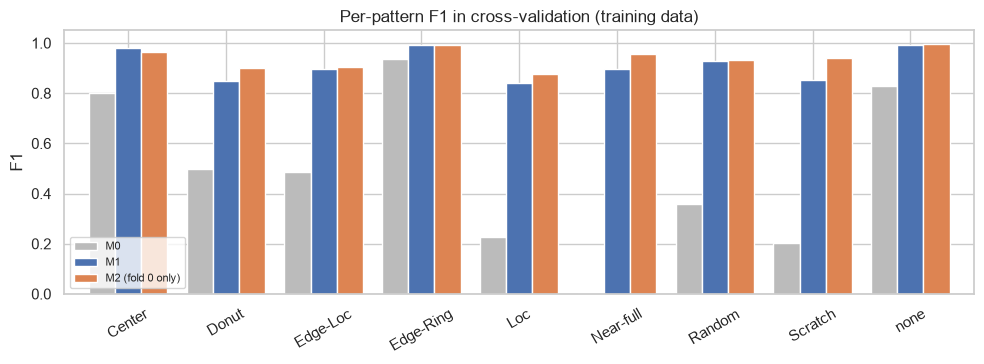

In [4]:
order = ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Near-full", "Random", "Scratch", "none"]
plot = per_class.reindex(order).rename(columns={"M2 (fold 0)": "M2 (fold 0 only)"})
fig, ax = plt.subplots(figsize=(10, 3.8))
plot.plot.bar(ax=ax, color=["#BBBBBB", "#4C72B0", "#DD8452"], width=0.8, rot=30)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1"); ax.set_title("Per-pattern F1 in cross-validation (training data)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_cv_per_class.png", dpi=150)
plot.round(3)

**해석**
- M0는 `Edge-Ring`(0.94), `none`(0.83), `Center`(0.80)를 크기만으로 맞힌다. 크기 지름길이 통하는 패턴들이다. `Near-full`은 0이다.
- M1과 M2의 차이가 가장 큰 패턴은 **Scratch(0.85 → 0.94)** 와 **Near-full(0.90 → 0.96)** 이다.
  Scratch는 휘거나 끊긴 선이라 "가장 큰 덩어리의 길쭉함" 같은 사람이 만든 특징으로는 다 잡히지 않는다. EDA에서 예상한 대로 CNN이 나을 수 있는 곳이다.
- **Loc(0.84~0.88)** 과 **Donut(0.85~0.90)** 은 두 모델 모두 상대적으로 낮다. Loc은 Edge-Loc과 위치만 다르고, Donut은 Center와 헷갈리기 쉽다.
- M2는 fold 0 하나의 값이라 M1(5-fold 전체 예측)과 표본이 다르다. 참고로만 본다.

## 3. CNN 학습 곡선: 학습률 고정 vs 코사인 스케줄

,마지막 10에폭 최저,마지막 10에폭 최고,사용한 모델의 점수
학습률 고정 (첫 학습),0.724,0.936,0.936
코사인 스케줄 (최종),0.933,0.940,0.940


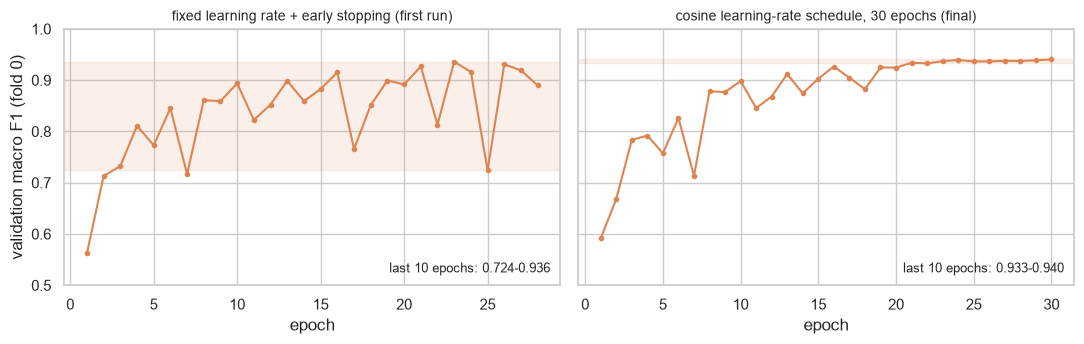

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (h, title) in zip(axes, [(history_fixed, "fixed learning rate + early stopping (first run)"),
                                 (history, "cosine learning-rate schedule, 30 epochs (final)")]):
    ax.plot(h.epoch, h.val_macro_f1, "o-", color="#DD8452", ms=3)
    ax.set_title(title, fontsize=10); ax.set_xlabel("epoch"); ax.set_ylim(0.5, 1.0)
    last = h.tail(10).val_macro_f1
    ax.axhspan(last.min(), last.max(), color="#DD8452", alpha=0.12)
    ax.text(0.98, 0.05, f"last 10 epochs: {last.min():.3f}-{last.max():.3f}", transform=ax.transAxes, ha="right", fontsize=9)
axes[0].set_ylabel("validation macro F1 (fold 0)")
fig.tight_layout(); fig.savefig(FIG_DIR / "07_cnn_history.png", dpi=150)

pd.DataFrame({
    "마지막 10에폭 최저": [history_fixed.tail(10).val_macro_f1.min(), history.tail(10).val_macro_f1.min()],
    "마지막 10에폭 최고": [history_fixed.tail(10).val_macro_f1.max(), history.tail(10).val_macro_f1.max()],
    "사용한 모델의 점수": [history_fixed.val_macro_f1.max(), history.val_macro_f1.iloc[-1]],
}, index=["학습률 고정 (첫 학습)", "코사인 스케줄 (최종)"]).round(3)

**해석**
- 첫 학습(왼쪽)은 학습률을 끝까지 고정해서 검증 점수가 에폭마다 0.72~0.94로 흔들렸다. 그때 고른 23에폭(0.936)은 흔들리다 한 번 높게 나온 지점이었다.
- 코사인 스케줄(오른쪽)은 학습률이 줄어들수록 흔들림이 줄고, 마지막 10에폭이 0.93~0.94에 모인다. 마지막 에폭(0.940)이 가장 높다.
- 흔들림의 원인이 과적합이 아니라 큰 학습률이었다는 짐작과 맞는다. 최종 모델은 학습 데이터 전체로 같은 방식(30에폭)으로 학습했다.

## 4. 고정한 결정

| 항목 | 값 |
|---|---|
| M0 | 고정 설정 (튜닝 없음) |
| M1 | `num_leaves=31`, `min_child_samples=20` |
| M2 | 코사인 스케줄 30에폭, 학습 데이터 전체로 학습한 가중치 `models/cnn_final.pt` |

이 결정과 CNN 가중치를 평가 데이터를 열기 전에 커밋한다.